# 02 Exploratory Data Analysis (EDA)

**Project:** Retail Sales Forecasting Using Machine Learning (Walmart Store Sales)
**Input:** `data/processed/merged_clean.parquet` (from notebook 01)
**Goal:** understand sales patterns before modelling. This notebook answers the first two research questions:

1. What historical sales patterns and seasonal trends exist?
2. Which variables (holidays, markdowns, store characteristics, economic indicators) appear to influence sales?


**Contents**
1. Setup and loading
2. Overall sales trend
3. Seasonality
4. Holiday effects
5. Store type and size
6. Departments
7. Store ranking
8. External factors (weather, fuel, CPI, unemployment)
9. Markdown (promotion) effect
10. Autocorrelation and lag relationships
11. Summary and implications for modelling

## 1. Setup and loading


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (11, 5)

PROCESSED = Path("../data/processed")
FIGS = Path("../reports/figures")
FIGS.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def millions(x, pos):
    return f"{x / 1e6:.1f}M"

In [3]:
df = pd.read_parquet(PROCESSED / "merged_clean.parquet")
df["Type"] = df["Type"].astype(str)

md_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
df["total_markdown"] = df[md_cols].sum(axis=1)
first_md = df.loc[df["has_markdown_data"] == 1, "Date"].min()

print(f"Rows: {len(df):,} | Stores: {df['Store'].nunique()} | Departments: {df['Dept'].nunique()}")
print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Markdown tracking starts:", first_md.date())
df.head()

Rows: 421,570 | Stores: 45 | Departments: 81
Date range: 2010-02-05 -> 2012-10-26
Markdown tracking starts: 2011-11-11


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,neg_sales,has_markdown_data,total_markdown
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,0,0,0.0
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,0,0,0.0
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,0,0,0.0
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,0,0,0.0
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,0,0,0.0


## 2. Overall sales trend
We add up sales across all stores and departments for every week to see the big picture: the long-term direction, the size of the peaks, and where the flagged holiday weeks fall.

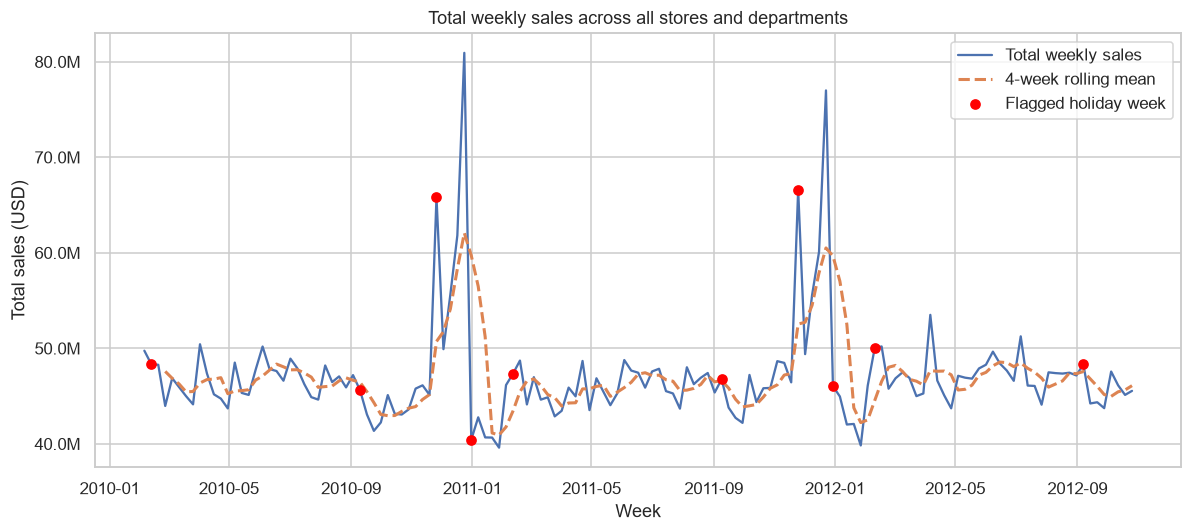

In [4]:
weekly = (
    df.groupby("Date")
      .agg(total_sales=("Weekly_Sales", "sum"), is_holiday=("IsHoliday", "max"))
      .reset_index()
)
weekly["roll4"] = weekly["total_sales"].rolling(4).mean()
weekly["year"] = weekly["Date"].dt.year
weekly["month"] = weekly["Date"].dt.month
weekly["week"] = (weekly["Date"].dt.day_of_year - 1) // 7 + 1

fig, ax = plt.subplots()
ax.plot(weekly["Date"], weekly["total_sales"], lw=1.5, label="Total weekly sales")
ax.plot(weekly["Date"], weekly["roll4"], lw=2, ls="--", label="4-week rolling mean")
hol = weekly[weekly["is_holiday"] == 1]
ax.scatter(hol["Date"], hol["total_sales"], color="red", zorder=3, label="Flagged holiday week")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Total weekly sales across all stores and departments")
ax.set_xlabel("Week")
ax.set_ylabel("Total sales (USD)")
ax.legend()
savefig("01_total_weekly_sales")

In [5]:
print("Top 5 weeks by total sales:")
display(weekly.nlargest(5, "total_sales")[["Date", "total_sales", "is_holiday"]].assign(total_sales=lambda x: x["total_sales"].round(0)))

print("Lowest 5 weeks by total sales:")
display(weekly.nsmallest(5, "total_sales")[["Date", "total_sales", "is_holiday"]].assign(total_sales=lambda x: x["total_sales"].round(0)))

# Like-for-like growth: Feb-Oct only, because 2010 starts in Feb and 2012 ends in Oct
cmp = weekly[weekly["month"].between(2, 10)].groupby("year")["total_sales"].mean()
growth = cmp.round(0).to_frame("avg_weekly_total")
growth["yoy_pct"] = (cmp.pct_change() * 100).round(2)
print("Average weekly total sales, Feb-Oct only:")
display(growth)

Top 5 weeks by total sales:


,Date,total_sales,is_holiday
46,2010-12-24,80931416.0,0
98,2011-12-23,76998241.0,0
94,2011-11-25,66593605.0,1
42,2010-11-26,65821003.0,1
45,2010-12-17,61820800.0,0


Lowest 5 weeks by total sales:


,Date,total_sales,is_holiday
51,2011-01-28,39599853.0,0
103,2012-01-27,39834975.0,0
47,2010-12-31,40432519.0,1
50,2011-01-21,40654648.0,0
49,2011-01-14,40673678.0,0


Average weekly total sales, Feb-Oct only:


,avg_weekly_total,yoy_pct
year,,
2010,46083903.0,NaN
2011,45801425.0,-0.61
2012,46954830.0,2.52


**Observations**
- Total weekly sales usually sit around 46 million USD per week, with sharp spikes in late November and December.
- The highest week is 2010-12-24 (total 80.9M). The lowest weeks fall in January(2011-01-14, 01-21, and 2012-01-27).
- Like-for-like (Feb-Oct) growth is -0.61% from 2010 to 2011 and 2.52% from 2011 to 2012, so the long-term trend is roughly flat to slightly rising.
- The spike pattern repeats every year, which points to strong yearly seasonality.

## 3. Seasonality

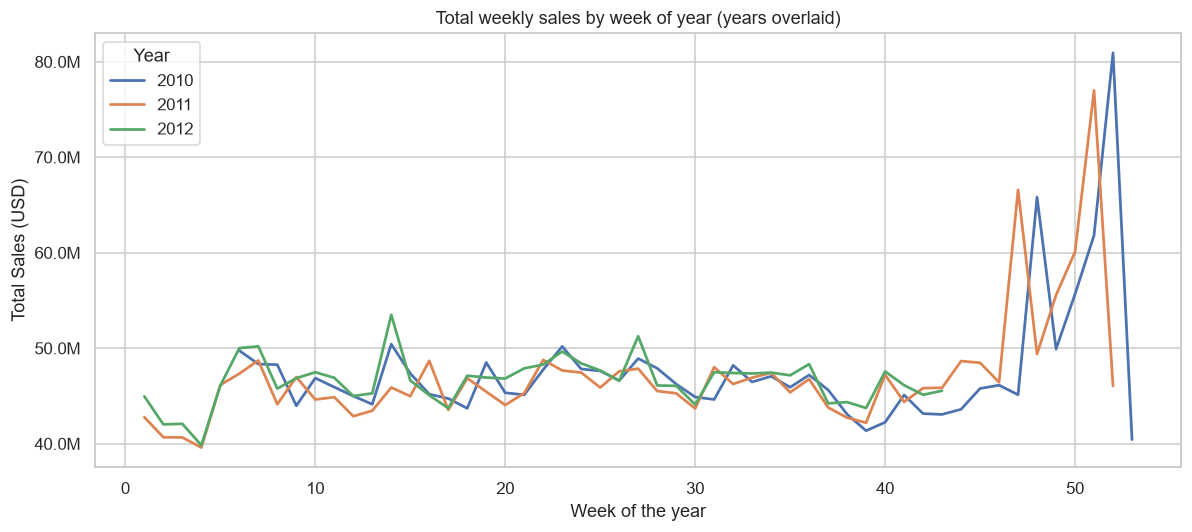

In [24]:
fig, ax = plt.subplots()

for year, sub in weekly.groupby("year"):
    ax.plot(sub["week"], sub["total_sales"], lw=1.8, label=str(year))
    
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_title("Total weekly sales by week of year (years overlaid)")
ax.set_xlabel("Week of the year")
ax.set_ylabel("Total Sales (USD)")
ax.legend(title="Year")

savefig("02_seasonality_overlay")

month
1     0.8824
2     1.0060
3     0.9679
4     0.9807
5     0.9854
6     1.0166
7     0.9855
8     1.0010
9     0.9450
10    0.9548
11    1.0958
12    1.2244
Average Seasonal Index:  1.0038


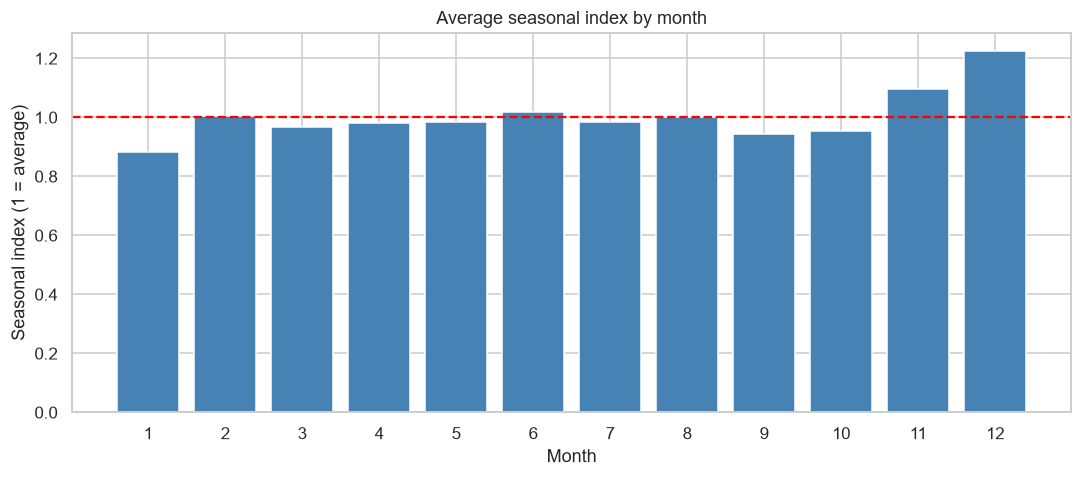


Months per year available:
      min  max
year          
2010    2   12
2011    1   12
2012    1   10

Average weekly sales by week of year: [51, 52]


In [7]:
month_idx = weekly.groupby("month")["total_sales"].mean() / weekly["total_sales"].mean()
print(month_idx.round(4).to_string())
print(f"Average Seasonal Index: ", (month_idx.sum()/12).round(4)) # 1.0038

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(month_idx.index, month_idx.values, color="steelblue")
ax.axhline(1, color="red", lw=1.5, ls="--")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Seasonal index (1 = average)")
ax.set_title("Average seasonal index by month")

savefig("03_seasonal_index_by_month")

print("\nMonths per year available:")
print(weekly.groupby("year")["month"].agg(["min", "max"]))

weekly_avg = weekly.groupby("week")["total_sales"].mean()
peak_week = weekly_avg.nlargest(2).index.tolist()
print("\nAverage weekly sales by week of year:", peak_week)


**Observations**
- The yearly shape (week-of-year overlay) is consistent across years: peaks line up around weeks 51 and 52.
- The strongest months are (12)December and (11)November (index 1.2244 and 1.0958). The weakest months are (1)January (index 0.8824).
- Caveat: 2010 starts in February and 2012 ends in October, so January, November and December have fewer years of data. Monthly indices for those months are based on 2 years.
- Implication: models need calendar features (month, week of year) and a lag of about 52 weeks.

## 4. Holiday Effects
The dataset flags four holiday events (Super Bowl, Labor Day, Thanksgiving, Christmas). In notebook 01 we found that the Christmas flag lands on the **week of Dec 30/31**, not on the pre-Christmas peak week (around Dec 24). Here we label the flagged events and add a custom **Pre-Christmas (NOT flagged)** week, then measure how each differs from a normal week.

**Lift** = total sales in the event week ÷ average of the previous 4 regular (non-event) weeks. A lift of 1.0 means no change.

In [8]:
d = weekly["Date"]

conds = [
    (weekly["is_holiday"] == 1) & (d.dt.month == 2),
    (weekly["is_holiday"] == 1) & (d.dt.month == 9),
    (weekly["is_holiday"] == 1) & (d.dt.month == 11),
    (weekly["is_holiday"] == 1) & (d.dt.month == 12),
    (weekly["is_holiday"] == 0) & (d.dt.month == 12) & d.dt.day.between(18, 25),
]

event_names = ["Super Bowl", "Labor Day", "Thanksgiving", "Christmas (flagged wk)", "Pre-Christmas (NOT flagged)"]
weekly["event"] = np.select(conds, event_names, default="Regular")

rows = []
for i, r in weekly[weekly["event"] != "Regular"].iterrows():
    prev = weekly.loc[max(0, i-4): i-1]
    prev = prev[prev["event"] == "Regular"]
    if len(prev) == 0:
        continue
    rows.append({
        "event": r["event"],
        "year": r["year"],
        "date": r["Date"].date(),
        "total_sales": round(r["total_sales"]),
        "baseline_avg": round(prev["total_sales"].mean()),
        "lift": round(r["total_sales"] / prev["total_sales"].mean(), 3),
    })
        
lift_df = pd.DataFrame(rows)
display(lift_df)

,event,year,date,total_sales,baseline_avg,lift
0,Super Bowl,2010,2010-02-12,48336678,49750740,0.972
1,Labor Day,2010,2010-09-10,45634398,46657342,0.978
2,Thanksgiving,2010,2010-11-26,65821003,45158799,1.458
3,Pre-Christmas (NOT flagged),2010,2010-12-24,80931416,55798866,1.450
4,Christmas (flagged wk),2010,2010-12-31,40432519,55798866,0.725
5,Super Bowl,2011,2011-02-11,47336193,41770323,1.133
6,Labor Day,2011,2011-09-09,46763228,46490122,1.006
7,Thanksgiving,2011,2011-11-25,66593605,47356143,1.406
8,Pre-Christmas (NOT flagged),2011,2011-12-23,76998241,55012467,1.400
9,Christmas (flagged wk),2011,2011-12-30,46042461,55012467,0.837


['Super Bowl', 'Labor Day', 'Thanksgiving', 'Christmas (flagged wk)', 'Pre-Christmas (NOT flagged)']


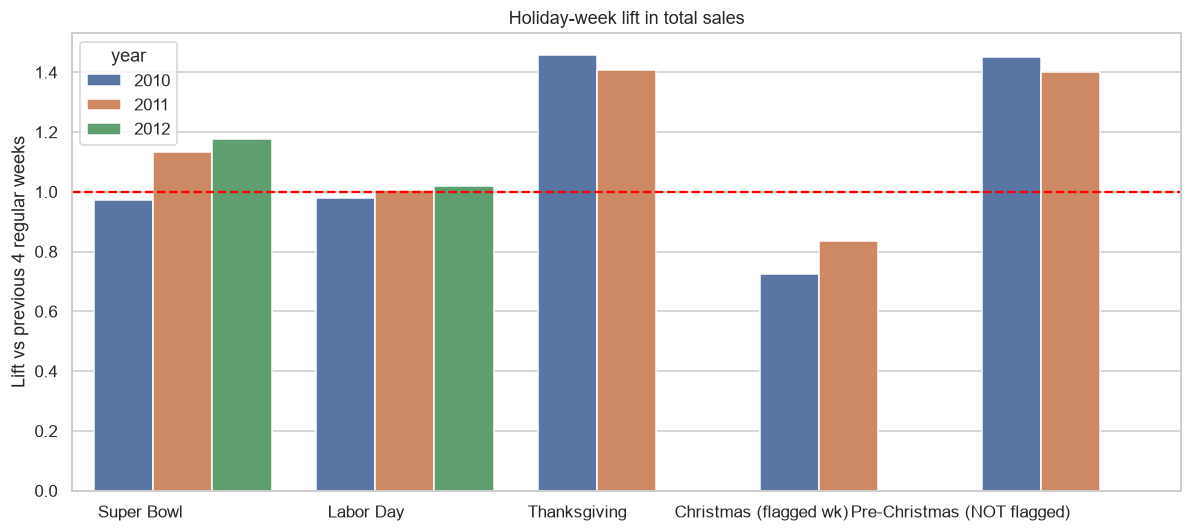

Average sales per row, flagged vs not flagged:
              mean  median   count
IsHoliday                         
0          15901.0  7590.0  391909
1          17036.0  7948.0   29661


In [9]:
order = [e for e in event_names if e in lift_df["event"].unique()]
print(order)

fig, ax = plt.subplots()
sns.barplot(data=lift_df, x="event", y="lift", hue="year", order=order, palette="deep", ax=ax)
ax.axhline(1, color="red", ls="--")
ax.set_xlabel("")
ax.set_ylabel("Lift vs previous 4 regular weeks")
ax.set_title("Holiday-week lift in total sales")
plt.setp(ax.get_xticklabels(), ha="right")
savefig("04_holiday_lift")

print("Average sales per row, flagged vs not flagged:")
print(df.groupby("IsHoliday")["Weekly_Sales"].agg(["mean", "median", "count"]).round(0))

### 4.1 Which departments react most?
Average sales in Thanksgiving and Pre-Christmas weeks compared with regular weeks, by department. Only departments with an average regular-week sale above 1,000 are shown, to avoid noisy ratios.

,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,neg_sales,has_markdown_data,total_markdown,event
0,1,1,2010-02-05,24924.50,0,A,151315,42.31,2.572,0.00,0.00,0.00,0.00,0.00,211.096358,8.106,0,0,0.00,Regular
1,1,1,2010-02-12,46039.49,1,A,151315,38.51,2.548,0.00,0.00,0.00,0.00,0.00,211.242170,8.106,0,0,0.00,Super Bowl
2,1,1,2010-02-19,41595.55,0,A,151315,39.93,2.514,0.00,0.00,0.00,0.00,0.00,211.289143,8.106,0,0,0.00,Regular
3,1,1,2010-02-26,19403.54,0,A,151315,46.63,2.561,0.00,0.00,0.00,0.00,0.00,211.319643,8.106,0,0,0.00,Regular
4,1,1,2010-03-05,21827.90,0,A,151315,46.50,2.625,0.00,0.00,0.00,0.00,0.00,211.350143,8.106,0,0,0.00,Regular
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,0,B,118221,64.88,3.997,4556.61,20.64,1.50,1601.01,3288.25,192.013558,8.684,0,1,9468.01,Regular
421566,45,98,2012-10-05,628.10,0,B,118221,64.89,3.985,5046.74,0.00,18.82,2253.43,2340.01,192.170412,8.667,0,1,9659.00,Regular
421567,45,98,2012-10-12,1061.02,0,B,118221,54.47,4.000,1956.28,0.00,7.89,599.32,3990.54,192.327265,8.667,0,1,6554.03,Regular
421568,45,98,2012-10-19,760.01,0,B,118221,56.47,3.969,2004.02,0.00,3.18,437.73,1537.49,192.330854,8.667,0,1,3982.42,Regular


event,Christmas (flagged wk),Labor Day,Pre-Christmas (NOT flagged),Regular,Super Bowl,Thanksgiving
Dept,,,,,,
1,16820.851000,15303.510593,49585.533444,18712.283250,28148.219630,16525.651111
2,37141.904556,45224.421926,61155.674222,43446.258665,42824.016667,41801.758889
3,7429.492222,19736.857926,15208.132556,11712.058249,9657.947556,9379.795556
4,24925.928333,27789.148519,30857.190556,25846.272682,25198.297926,28990.912778
5,28038.090000,14975.605188,77784.170674,19662.459928,24675.874091,74191.033933
...,...,...,...,...,...,...
95,55214.174556,74814.880296,73074.370222,70016.494623,68278.508963,63437.223778
96,17132.230429,16515.045728,19893.492000,15009.716808,14624.980400,20611.767121
97,11741.875227,16317.584580,15703.347045,14252.571777,14556.562061,12000.298523


,regular_avg,thanksgiving_lift,pre_christmas_lift
Dept,,,
72,45938.82,5.28,2.86
6,4278.12,4.82,4.57
18,6488.61,4.24,4.31
55,9663.23,3.79,4.88
5,19662.46,3.77,3.96
7,22024.46,3.32,6.07
14,14029.57,2.63,3.21
48,1268.30,2.19,3.39
24,6160.92,2.07,2.37


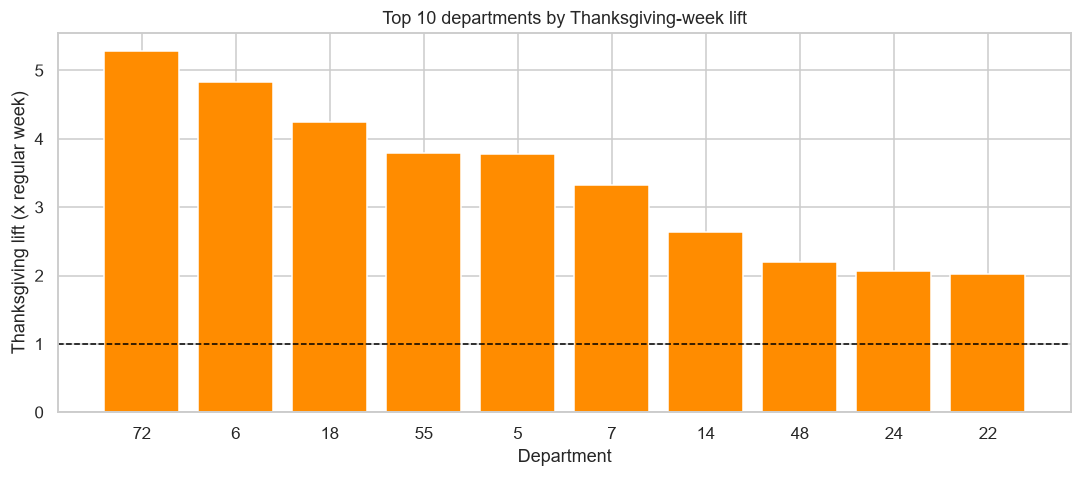

In [10]:
tmp = df.merge(weekly[["Date", "event"]], on="Date")
display(tmp)
dept_mean = tmp.groupby(["Dept", "event"])["Weekly_Sales"].mean().unstack()
display(dept_mean)

dept_lift = pd.DataFrame({
    "regular_avg": dept_mean["Regular"],
    "thanksgiving_lift": dept_mean["Thanksgiving"] / dept_mean["Regular"],
    "pre_christmas_lift": dept_mean["Pre-Christmas (NOT flagged)"] / dept_mean["Regular"],
})
dept_lift = dept_lift[dept_lift["regular_avg"] > 1000].sort_values("thanksgiving_lift", ascending=False)

display(dept_lift.head(10).round(2))

top = dept_lift.head(10)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(top.index.astype(str), top["thanksgiving_lift"], color="darkorange")
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_xlabel("Department")
ax.set_ylabel("Thanksgiving lift (x regular week)")
ax.set_title("Top 10 departments by Thanksgiving-week lift")
savefig("05_dept_thanksgiving_lift")


**Observations**
- Thanksgiving week lifts total sales by about 1.4-1.5x (1.46x in 2010, 1.41x in 2011) compared with the previous 4 regular weeks. Super Bowl and Labor Day lifts are small or flat (Super Bowl 0.97x, 1.13x and 1.18x for 2010-2012; Labor Day 0.98x, 1.01x and 1.02x), which is why the flagged-vs-not-flagged average gap is small (17,036 vs 15,901 per row, only about 7% higher).
- The flagged Christmas week (Dec 30/31) is **below** the December baseline (0.73x in 2010, 0.84x in 2011), while the unflagged week before Christmas (Dec 24 / Dec 23) has a lift of about 1.45x and 1.40x, reaching 80.9M and 77.0M in total sales, the two highest weeks in the dataset. So the dataset's holiday flag **misses** the biggest December peak.
- Departments with the strongest Thanksgiving response: Dept 72 (5.3x a regular week), Dept 6 (4.8x), Dept 18 (4.2x), Dept 55 (3.8x) and Dept 5 (3.8x). Among these, the pre-Christmas week is strongest for Dept 7 (6.1x), Dept 55 (4.9x) and Dept 6 (4.6x).
- Caveats: the 2010 Super Bowl baseline rests on a single prior week because the data starts on 2010-02-05, and 2012 has only two events because the data ends in October. The December baseline already includes the early-December shopping build-up, so the Christmas lifts are conservative.
- Implication: besides `IsHoliday`, create our own features for Thanksgiving week, pre-Christmas week and the week after, and keep the flagged weeks in WMAE evaluation (they count 5x).

## 5. Store type and size
Walmart stores come in types A, B and C and differ in size. We aggregate to **store-week totals** (all departments added) and compare by type. Note that stores do not carry the same number of departments, which also affects store totals.

In [11]:
store_week = df.groupby(["Store", "Date"], as_index=False)["Weekly_Sales"].sum()
display(store_week.head())

store_info = (
    store_week.groupby("Store")["Weekly_Sales"].mean().rename("avg_weekly_sales").reset_index()
    .merge(df[["Store", "Type", "Size"]].drop_duplicates(), on="Store")
    .merge(df.groupby("Store")["Dept"].nunique().rename("n_depts").reset_index(), on="Store")
)

type_sum = store_info.groupby("Type").agg(
    n_stores=("Store", "count"),
    avg_size=("Size", "mean"),
    avg_weekly_sales=("avg_weekly_sales", "mean"),
    avg_depts=("n_depts", "mean"),   
).round(2)

type_sum["share_of_total_sales_pct"] = (
    df.groupby("Type")["Weekly_Sales"].sum() / df["Weekly_Sales"].sum() * 100
).round(2)
display(type_sum)

print("Correlation with store average weekly sales:")
print(f"  Size vs sales:     {store_info['Size'].corr(store_info['avg_weekly_sales']):.3f}")
print(f"  Depts vs sales:    {store_info['n_depts'].corr(store_info['avg_weekly_sales']):.3f}")

,Store,Date,Weekly_Sales
0,1,2010-02-05,1643690.90
1,1,2010-02-12,1641957.44
2,1,2010-02-19,1611968.17
3,1,2010-02-26,1409727.59
4,1,2010-03-05,1554806.68


,n_stores,avg_size,avg_weekly_sales,avg_depts,share_of_total_sales_pct
Type,,,,,
A,22,177247.73,1376673.47,75.95,64.28
B,17,101190.71,822994.96,75.65,29.70
C,6,40541.67,472614.83,62.33,6.02


Correlation with store average weekly sales:
  Size vs sales:     0.846
  Depts vs sales:    0.638


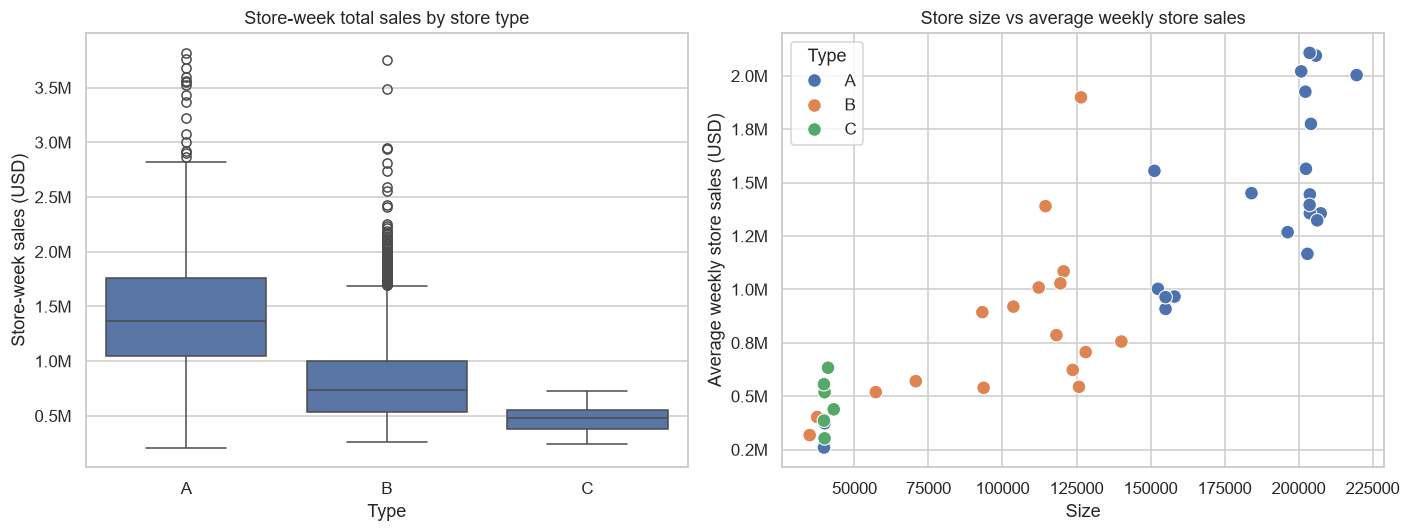

In [12]:
type_order = ["A", "B", "C"]
sw_type = store_week.merge(store_info[["Store", "Type"]], on="Store")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=sw_type, x="Type", y="Weekly_Sales", order=type_order, ax=axes[0])
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(millions))
axes[0].set_title("Store-week total sales by store type")
axes[0].set_ylabel("Store-week sales (USD)")

sns.scatterplot(data=store_info, x="Size", y="avg_weekly_sales", hue="Type",
                hue_order=type_order, s=80, ax=axes[1])
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(millions))
axes[1].set_title("Store size vs average weekly store sales")
axes[1].set_ylabel("Average weekly store sales (USD)")
savefig("06_store_type_and_size")

   **Observations**
   - Type A has the highest sales per store (about 1.38M per week) and the largest average size (about 177,000 sq ft). Type B averages 0.82M (size ≈ 101,000) and Type C 0.47M (size ≈ 41,000).
   - Type A is 22 of 45 stores (49%) but produces 64.3% of total sales; Type B is 17 stores with 29.7%, and Type C is 6 stores with 6.0%.
   - Size and average weekly store sales are strongly correlated (r = 0.846). The number of departments carried is also related (r = 0.638); Type C stores average about 62 departments versus about 76 for A and B.
   - Implication: `Type` and `Size` are useful predictors and should be kept as features.

## 6. Departments

Walmart sells across 81 departments, but a small set drives most revenue. We aggregate weekly sales by department and check how concentrated the sales are.


Top 10 departments = 46.0% of all sales
Departments needed to reach 80% of sales: 29 of 81


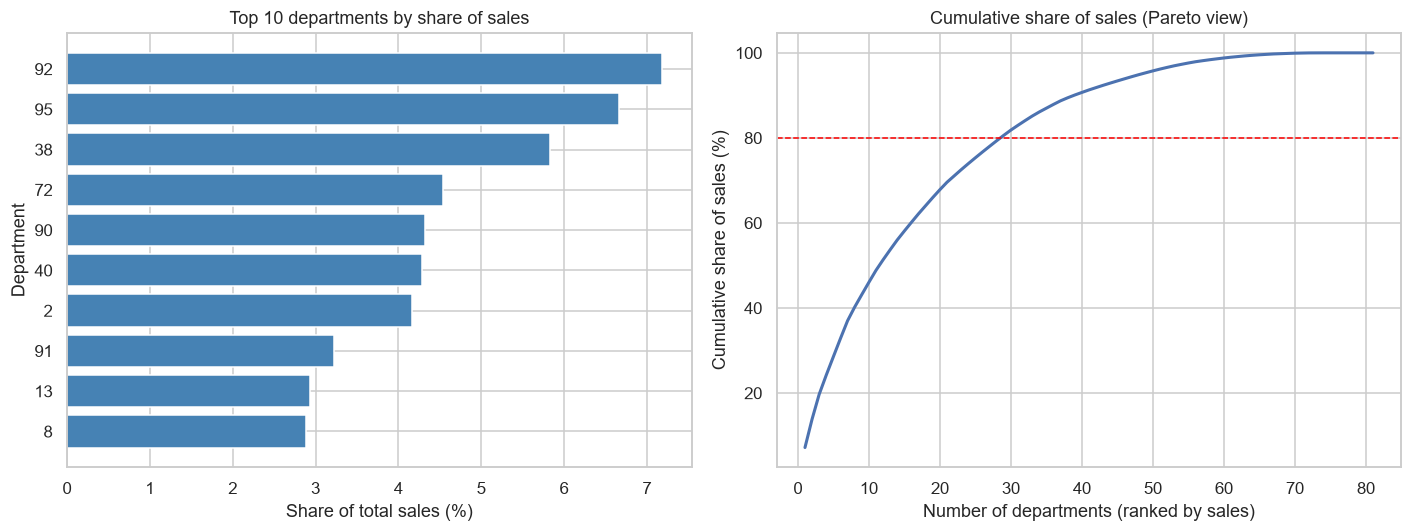

In [13]:
dept_total = df.groupby("Dept")["Weekly_Sales"].sum().sort_values(ascending=False)
dept_share = dept_total / dept_total.sum() * 100
cum_share = dept_share.cumsum()

n80 = int((cum_share < 80).sum() + 1)
print(f"Top 10 departments = {dept_share.head(10).sum():.1f}% of all sales")
print(f"Departments needed to reach 80% of sales: {n80} of {len(dept_total)}")

top10 = dept_share.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top10.index.astype(str)[::-1], top10.values[::-1], color="steelblue")
axes[0].set_xlabel("Share of total sales (%)")
axes[0].set_ylabel("Department")
axes[0].set_title("Top 10 departments by share of sales")

axes[1].plot(range(1, len(cum_share) + 1), cum_share.values, lw=2)
axes[1].axhline(80, color="red", ls="--", lw=1)
axes[1].set_xlabel("Number of departments (ranked by sales)")
axes[1].set_ylabel("Cumulative share of sales (%)")
axes[1].set_title("Cumulative share of sales (Pareto view)")
savefig("07_department_concentration")

In [23]:
display(dept_share.head(3).round(2))

Dept
92    7.18
95    6.67
38    5.84
Name: Weekly_Sales, dtype: float64

   **Observations**
   - The top 10 departments account for 46.0% of sales, and 29 of 81 departments make up 80%.
   - The largest department is Dept(92) with 7.18% of sales.

## 7. Store ranking

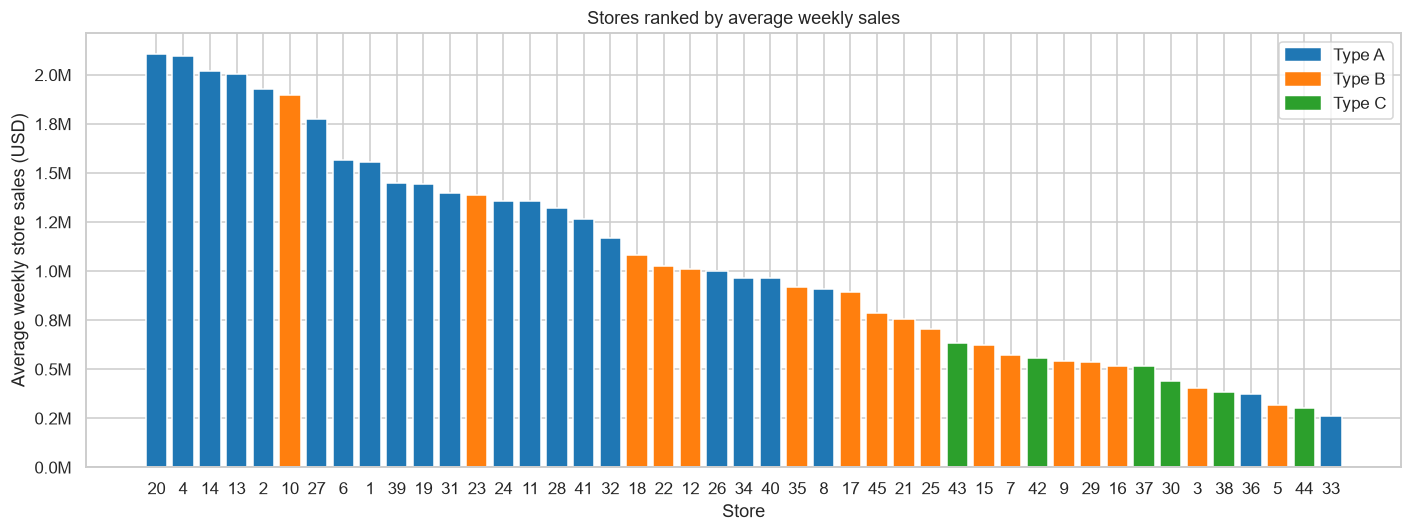

Top 5 stores: [20, 4, 14, 13, 2]
Bottom 5 stores: [38, 36, 5, 44, 33]
Highest / lowest store ratio: 8.1x


In [15]:
si = store_info.sort_values("avg_weekly_sales", ascending=False)
colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#2ca02c"}

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(si["Store"].astype(str), si["avg_weekly_sales"], color=si["Type"].map(colors))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions))
ax.set_xlabel("Store")
ax.set_ylabel("Average weekly store sales (USD)")
ax.set_title("Stores ranked by average weekly sales")
ax.legend(handles=[Patch(color=c, label=f"Type {t}") for t, c in colors.items()])
savefig("08_store_ranking")

print("Top 5 stores:", si["Store"].head(5).tolist())
print("Bottom 5 stores:", si["Store"].tail(5).tolist())
print(f"Highest / lowest store ratio: {si['avg_weekly_sales'].max() / si['avg_weekly_sales'].min():.1f}x")

**Observations**
- Stores 20, 4 and 14 lead; stores 44 and 33 are the lowest.
- The best store sells about 8.1x as much as the smallest.
- Implication: stores differ a lot in level, so Store (or store-level averages) must be available to the models.


## 8. External factors: temperature, fuel price, CPI, unemployment
Stores differ in size, so raw sales are not comparable. We build a **sales index** per store-week: sales divided by that store's own average (1.0 = a normal week for that store). We then check how the index relates to each factor. Spearman correlation is used because it does not assume a straight-line relationship.

**Caution:** Fuel price and CPI rise over time and unemployment falls over time, so their correlations with sales can partly reflect *time* rather than a real effect.

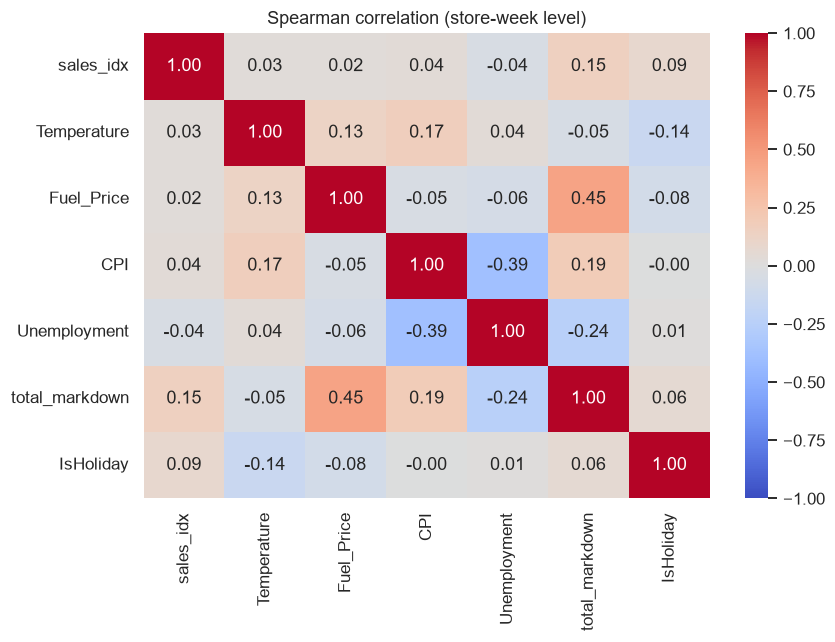

Correlation with sales index:
total_markdown    0.151
IsHoliday         0.085
Unemployment     -0.044
CPI               0.038
Temperature       0.030
Fuel_Price        0.024


In [16]:
sw = df.groupby(["Store", "Date"], as_index=False).agg(
    sales=("Weekly_Sales", "sum"),
    Temperature=("Temperature", "first"),
    Fuel_Price=("Fuel_Price", "first"),
    CPI=("CPI", "first"),
    Unemployment=("Unemployment", "first"),
    total_markdown=("total_markdown", "first"),
    IsHoliday=("IsHoliday", "first"),
)
sw["sales_idx"] = sw["sales"] / sw.groupby("Store")["sales"].transform("mean")

factors = ["Temperature", "Fuel_Price", "CPI", "Unemployment", "total_markdown", "IsHoliday"]
corr = sw[["sales_idx"] + factors].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (store-week level)")
savefig("09_correlation_heatmap")

print("Correlation with sales index:")
print(corr["sales_idx"].drop("sales_idx").sort_values(key=abs, ascending=False).round(3).to_string())

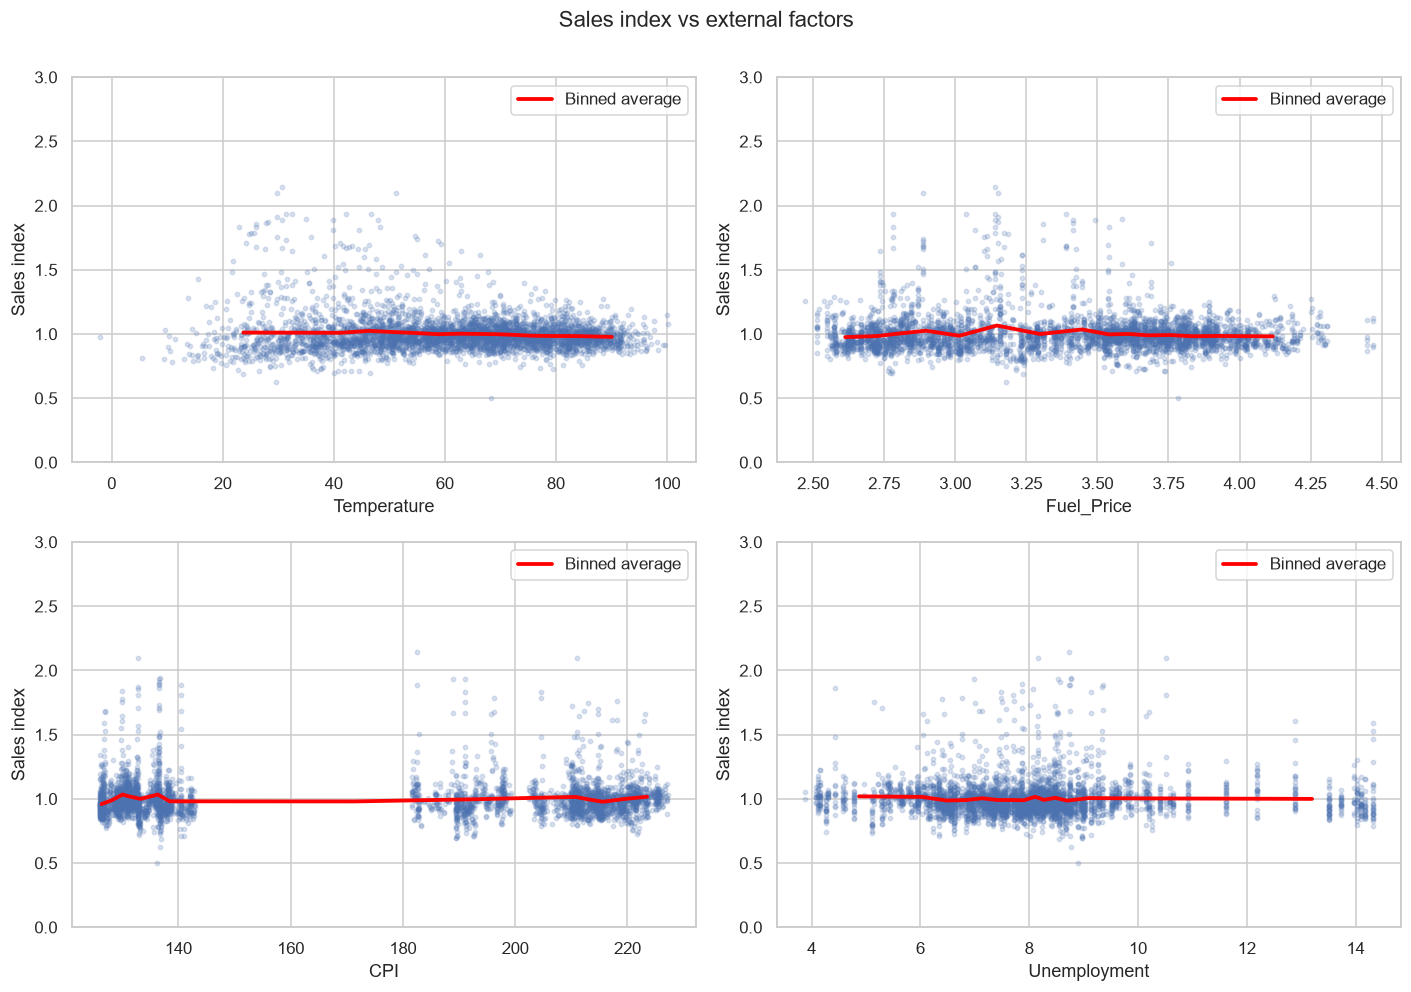

In [17]:
# Binned relationship: average sales index per bin of each factor
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), ["Temperature", "Fuel_Price", "CPI", "Unemployment"]):
    sample = sw.sample(4000, random_state=42)
    ax.scatter(sample[col], sample["sales_idx"], s=8, alpha=0.2)
    bins = pd.qcut(sw[col], 15, duplicates="drop")
    trend = sw.groupby(bins, observed=True).agg(x=(col, "mean"), y=("sales_idx", "mean"))
    ax.plot(trend["x"], trend["y"], color="red", lw=2.5, label="Binned average")
    ax.set_xlabel(col)
    ax.set_ylabel("Sales index")
    ax.set_ylim(0, 3)
    ax.legend()
fig.suptitle("Sales index vs external factors", y=1.0)
savefig("10_external_factors")

   **Observations**
   - All relationships are weak: the largest correlation with the sales index is total markdown (ρ = 0.151), then the holiday flag (ρ = 0.085). Unemployment (−0.044), CPI (0.038), temperature (0.030) and fuel price (0.024) are all close to zero.
   - The +0.151 for markdown is inflated: markdown tracking only starts in Nov 2011 (right before the holiday peak), so it overlaps with holiday weeks and with the earlier weeks recorded as 0. When we restrict to non-holiday weeks after tracking began (section 9), the correlation is slightly negative (−0.034).
   - Fuel price, CPI and unemployment move slowly over time, so even these small correlations may reflect time rather than a real effect.
   - Implication: keep the factors as candidate features, but calendar, holiday and lag features are expected to matter far more.

## 9. Markdown (promotion) effect
Markdown data exists only from the tracking start date. We look only at that period and at **non-holiday weeks**, so holiday spikes do not distort the comparison. Weeks are split into four equal groups by total markdown amount.

,avg_markdown,avg_sales_idx,median_sales_idx,weeks
md_group,,,,
Q1 (lowest),2383.089,1.025,1.009,529
Q2,8506.100,1.021,0.983,529
Q3,15467.465,1.002,0.995,528
Q4 (highest),37466.741,1.002,0.997,529


Spearman correlation (markdown vs sales index, non-holiday weeks): -0.034


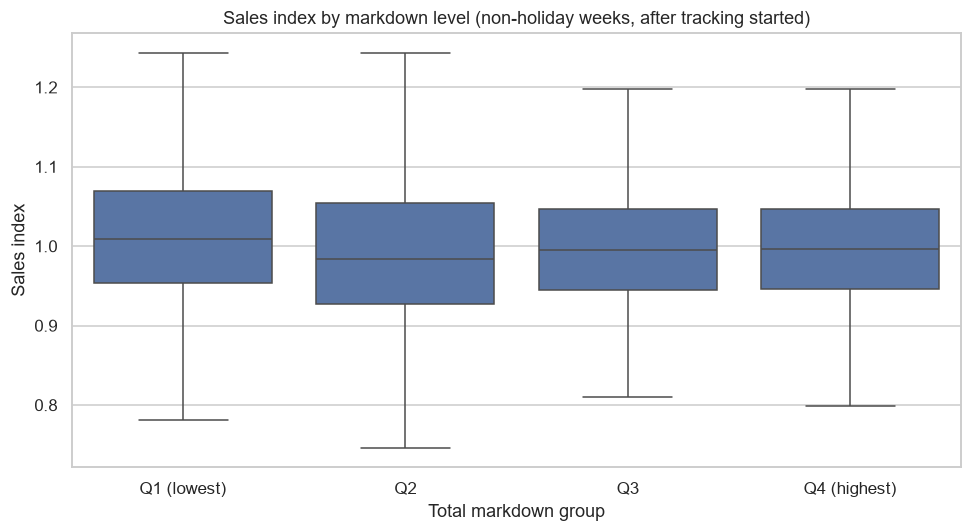

In [18]:
mk = sw[(sw["Date"] >= first_md) & (sw["IsHoliday"] == 0)].copy()
mk["md_group"] = pd.qcut(mk["total_markdown"].rank(method="first"), 4,
                         labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

summary = mk.groupby("md_group", observed=True).agg(
    avg_markdown=("total_markdown", "mean"),
    avg_sales_idx=("sales_idx", "mean"),
    median_sales_idx=("sales_idx", "median"),
    weeks=("sales_idx", "size"),
).round(3)
display(summary)
print(f"Spearman correlation (markdown vs sales index, non-holiday weeks): "
      f"{mk['total_markdown'].corr(mk['sales_idx'], method='spearman'):.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=mk, x="md_group", y="sales_idx", showfliers=False, ax=ax)
ax.set_xlabel("Total markdown group")
ax.set_ylabel("Sales index")
ax.set_title("Sales index by markdown level (non-holiday weeks, after tracking started)")
savefig("11_markdown_effect")

**Observations**
- Weeks with the highest markdowns have an average sales index of 1.002 versus 1.025 for the lowest group.
- The correlation is weak and slightly negative (ρ = -0.034), i.e. a weak inverse relationship.
- Limitation: markdown data covers only about 2,115 store-week observations, and promotions are not randomly assigned (stores may run more promotions in already busy periods), so this shows association, not cause.
- Implication: include markdown features with the `has_markdown_data` flag, but do not rely on them alone.


## 10. Autocorrelation and lag relationships
Forecasting models often rely on past values. We check (1) how the **total** weekly sales series relates to its own past (autocorrelation), and (2) how each **store–department** weekly value relates to its value 1, 2, 4, 13, 26 and 52 weeks earlier.

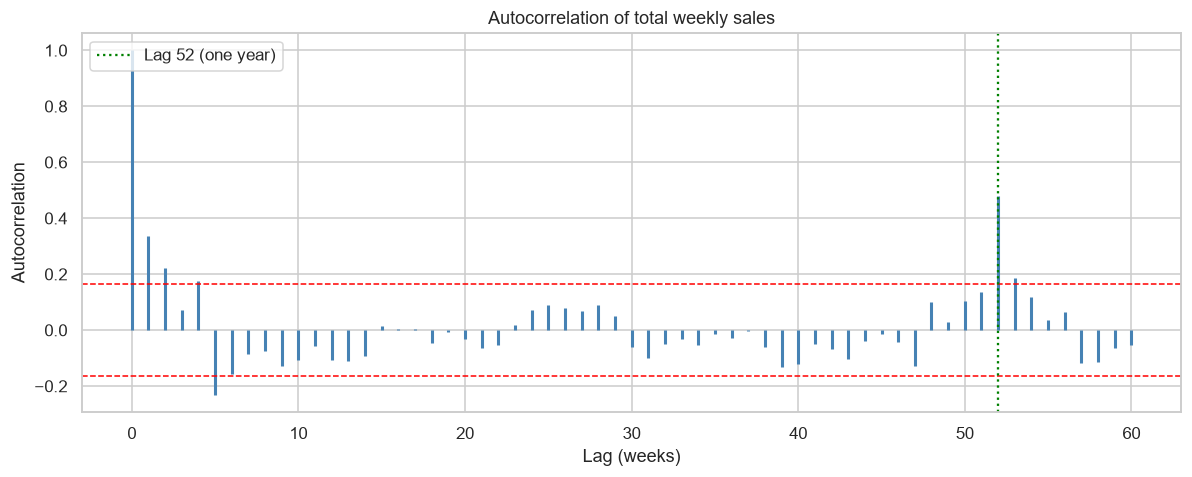

ACF at lag 1: 0.337 | lag 52: 0.479 (95% band: +/-0.164)


In [19]:
def acf(x, nlags):
    x = np.asarray(x, dtype=float) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[: len(x) - k] * x[k:]) / denom for k in range(nlags + 1)])

nlags = 60
vals = acf(weekly["total_sales"].values, nlags)
conf = 1.96 / np.sqrt(len(weekly))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.vlines(range(nlags + 1), 0, vals, color="steelblue", lw=2)
ax.axhline(conf, color="red", ls="--", lw=1)
ax.axhline(-conf, color="red", ls="--", lw=1)
ax.axvline(52, color="green", ls=":", lw=1.5, label="Lag 52 (one year)")
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of total weekly sales")
ax.legend()
savefig("12_acf_total_sales")

print(f"ACF at lag 1: {vals[1]:.3f} | lag 52: {vals[52]:.3f} (95% band: +/-{conf:.3f})")

,lag_weeks,pairs,correlation,mae_if_lag_used_as_forecast
0,1,412792,0.949,2128.0
1,2,409324,0.936,2582.0
2,4,402778,0.933,2772.0
3,13,375037,0.897,3691.0
4,26,337093,0.887,3890.0
5,52,261541,0.983,1930.0


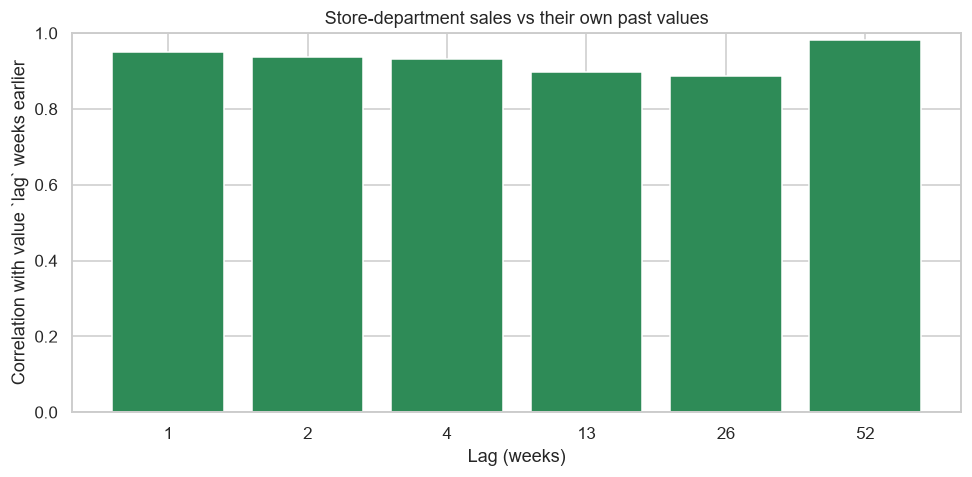

In [20]:
base = df[["Store", "Dept", "Date", "Weekly_Sales"]]
rows = []
for lag in [1, 2, 4, 13, 26, 52]:
    lagged = base.copy()
    lagged["Date"] = lagged["Date"] + pd.Timedelta(weeks=lag)
    m = base.merge(lagged, on=["Store", "Dept", "Date"], suffixes=("", "_lag"))
    rows.append({
        "lag_weeks": lag,
        "pairs": len(m),
        "correlation": round(m["Weekly_Sales"].corr(m["Weekly_Sales_lag"]), 3),
        "mae_if_lag_used_as_forecast": round((m["Weekly_Sales"] - m["Weekly_Sales_lag"]).abs().mean(), 0),
    })
lag_df = pd.DataFrame(rows)
display(lag_df)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(lag_df["lag_weeks"].astype(str), lag_df["correlation"], color="seagreen")
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Correlation with value `lag` weeks earlier")
ax.set_ylim(0, 1)
ax.set_title("Store-department sales vs their own past values")
savefig("13_lag_correlation")

**Observations**
- The total weekly series has a clear autocorrelation spike at lag 52 (≈ one year): 0.479 at lag 52 versus 0.337 at lag 1, both above the 95% band (±0.164).
- At store–department level, lag 1 has correlation 0.949 and lag 52 has 0.983. As a forecast, the value from 52 weeks earlier has the lowest error of all lags tested (MAE 1,930, versus 2,128 for lag 1 and 3,691 for lag 13), although lag 52 is measured on fewer rows (261,541 pairs) because it needs a year of history.
- This is a preview of the seasonal-naive baseline; the proper version with WMAE is in notebook 03.
- Implication: `lag_52` and same-week-last-year features should be core features. `lag_1` is only usable for one-step-ahead forecasts; for a multi-week horizon, features must come from data at least as old as the horizon.

## 11. Summary and implications for modelling

### Answer to Research Question 1 – patterns and seasonality
- Trend: roughly flat to slightly rising (Feb-Oct growth was -0.61% in 2010→2011 and +2.52% in 2011→2012).
- Seasonality: strong yearly seasonality, peaking in weeks 51–52 (pre-Christmas), with a secondary peak at Thanksgiving (week 47)
- Holidays: Thanksgiving lifts sales by ~1.46x; the pre-Christmas week (not flagged) lifts by ~1.4x; the flagged Christmas week (Dec 30/31) is below the baseline (0.73x–0.84x).

### Answer to Research Question 2 – influential variables
| Variable | Evidence | Expected usefulness |
|---|---|---|
| Calendar (week, month) | Strong yearly pattern with peaks in late Nov/Dec; strongest months are Dec (1.2244) and Nov (1.0958), weakest is Jan (0.8824) | High |
| Holiday / custom holiday weeks | Thanksgiving ~1.46x lift; pre-Christmas week ~1.4x; flagged Christmas week below baseline (0.73x–0.84x) | High |
| Store `Type` and `Size` | Type A stores average ~1.38M per week vs Type C ~0.47M; size vs sales correlation r = 0.846 | High |
| Department | Top 10 departments account for 46.0% of sales; 29 of 81 departments reach 80% of total sales | High |
| Lag values (1, 52) | ACF at lag 52 = 0.479; store-department correlation 0.983 (lag 52) vs 0.949 (lag 1); MAE 1,930 (lag 52) vs 2,128 (lag 1) | High |
| Markdowns | Weak overall (ρ = 0.151 across all weeks, driven by holiday weeks; ρ = −0.034 for non-holiday weeks after tracking began) | Medium |
| Temperature | Near-zero correlation with sales index (ρ = 0.030) | Low–Medium |
| Fuel price, CPI, unemployment | Near-zero / weak effects (Fuel ρ = 0.024; CPI ρ = 0.038; Unemployment ρ = -0.044) | Low |

### Decisions for feature engineering (notebook 04)
- Calendar features: year, month, week of year, week of month.
- Holiday features: flagged `IsHoliday`, plus custom flags for Thanksgiving week, pre-Christmas week and week after.
- Lag features: Lag features depend on the forecast horizon: for a 39-week horizon use lag_52, a same-week-last-year average (weeks 51–53) and training-period series averages. lag_1/2/4 and short rolling means are only allowed for one-step-ahead forecasts.
- Store features: `Type`, `Size`, store average sales (computed on the training period only).
- Promotion features: markdowns + `has_markdown_data`.
- Short series (under 52 weeks): fallback rule needed because `lag_52` does not exist.
